In [2]:
import numpy as np
import matplotlib.pyplot as plt
from bandit import BanditGames
from multi_level_rl import ParametricPopulation
import torch

import matplotlib.gridspec as gridspec

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

plt.rcParams["text.latex.preamble"] = r"\usepackage{lmodern} \usepackage{amsmath}"
# Options
params = {
    "text.usetex": True,
    "font.size": 15,
    "font.family": "lmodern",
    #   'text.latex.unicode': True,
}
plt.rcParams.update(params)

In [ ]:
bandit = BanditGames(game="rps")
population = ParametricPopulation(




random_policy = torch.ones(bandit.num_actions) / bandit.num_actions

population_size = 10

actions = torch.multinomial(random_policy, population_size, replacement=True)

# pair half the actions with the other half and then append the mirrored actions to the end of the actions

actions_pair = torch.cat(
    (
        actions[: population_size // 2].unsqueeze(1),
        actions[population_size // 2 :].unsqueeze(1),
    ),
    1,
)

full_actions = torch.cat((actions_pair, actions_pair.flip(1)), 0)

full_actions

rewards = bandit.pull(full_actions)



tensor([ 0., -1., -1.,  0., -1.,  0.,  1.,  1.,  0.,  1.])

In [3]:
full_actions

tensor([[0, 0],
        [0, 1],
        [1, 2],
        [0, 0],
        [1, 2],
        [0, 0],
        [1, 0],
        [2, 1],
        [0, 0],
        [2, 1]])

In [4]:
size = 1000
arms = 2

params = torch.zeros((size, arms))

policies = torch.sigmoid(params)

In [5]:
policies

tensor([[0.5000, 0.5000],
        [0.5000, 0.5000],
        [0.5000, 0.5000],
        ...,
        [0.5000, 0.5000],
        [0.5000, 0.5000],
        [0.5000, 0.5000]])

In [14]:
from utils import init_logits

params = init_logits(N=10000, A=3, r=0.2)

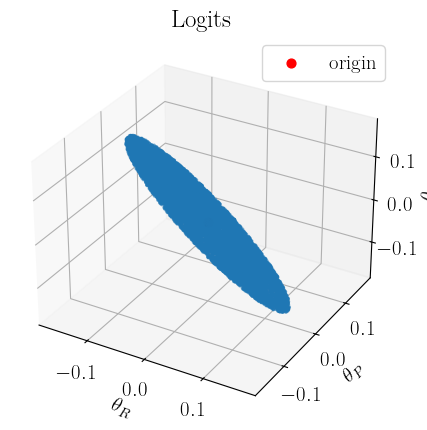

In [15]:
fig = plt.figure(figsize=(11, 5))

ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(*params.T, s=3, alpha=0.5)
ax.scatter(0, 0, 0, color="red", s=40, label="origin")
ax.set_xlabel(r"$\theta_R$")
ax.set_ylabel(r"$\theta_P$")
ax.set_zlabel(r"$\theta_S$")
ax.set_title("Logits")
ax.legend()